# Results walkthrough

Hourly bike-sharing demand: interpretable count models and uncertainty under temporal shift

This notebook **reads the already-computed results** so it stays fast. To
reproduce every number from the raw data, run `python -m src.run_analysis` in
the project root, then `python report/build_docs.py`.

**Scope.** Task A = demand modelling conditional on same-hour weather.
Task B = deployable forecasting using only calendar and lagged demand.
The final 15% of the series is a held-out (frozen) test period: it is never used for model or interval selection, and test results are reported once, after all choices are fixed on validation data.

**Headline.** Poisson GLM one-step-ahead test MAE **41.79** vs
168.89 (global mean), 66.48 (best naive, t-168h) and
55.21 (XGBoost, lag features). Best interval method by
validation Winkler score: **Split / Poisson-scaled**.


In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import Image, display
ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
RES = ROOT / "results"
pd.set_option("display.width", 160)


## 1. Data integrity and chronological split

,Period,Start,End,N hours,Mean cnt,Missing hours
0,Train,2011-01-01 00:00:00,2012-05-26 23:00:00,12163,159.9,125
1,Validation,2012-05-27 00:00:00,2012-09-12 23:00:00,2616,281.6,0
2,Test,2012-09-13 00:00:00,2012-12-31 23:00:00,2600,234.9,40


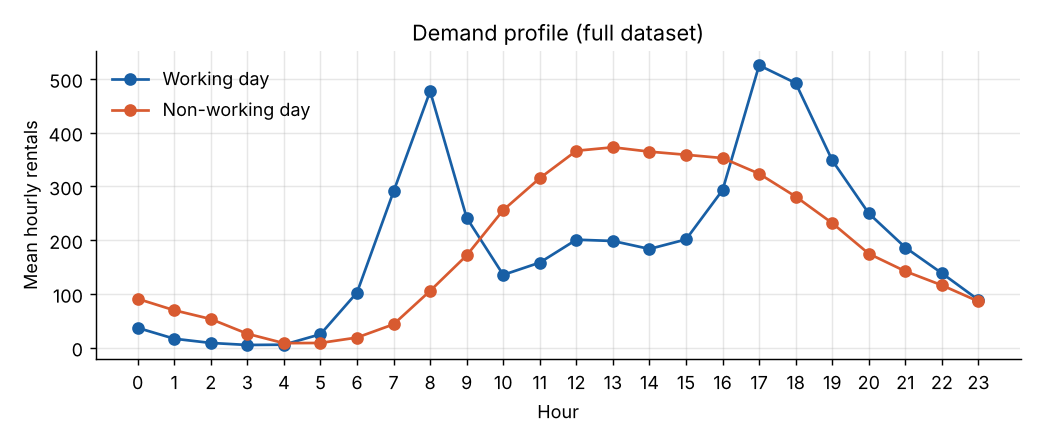

In [2]:
display(pd.read_csv(RES / "01_data_and_split.csv"))
display(Image(filename=str(RES / "figures" / "demand_profile.png")))


## 2. Task A: conditional model and correct inference
Pearson dispersion = 11.56; standard errors below are dispersion-corrected. The quadratic temperature term is interpreted jointly (see the report), never as a standalone exp(coef) rate ratio.

,Term,coef,quasi SE,quasi z,exp(coef) (single terms only)
0,temp,4.052,0.086,47.124,n/a (joint quadratic pair)
1,I(temp ** 2),-2.642,0.081,-32.544,n/a (joint quadratic pair)
2,hum,-0.233,0.017,-14.046,0.792
3,windspeed,-0.297,0.021,-14.270,0.743
4,C(yr)[T.1],0.515,0.006,78.946,1.673
5,C(weather)[T.2],-0.065,0.006,-10.199,0.937
6,C(weather)[T.3],-0.543,0.012,-44.433,0.581
7,holiday,-0.137,0.017,-8.074,0.872


,Model,MAE,RMSE,Poisson deviance
0,Poisson + yr:month,47.49,74.05,15.06
1,Poisson GLM (conditional),53.14,82.87,16.67
2,Seasonal naive (t-168h),57.62,97.92,32.45
3,NB GLM (conditional),61.65,96.90,20.64
4,Naive (t-24h),81.92,137.24,65.78
5,Naive (t-1h),92.22,135.39,57.87
6,Hour x workingday mean,124.79,165.93,89.09
7,Global mean,193.73,253.58,262.74


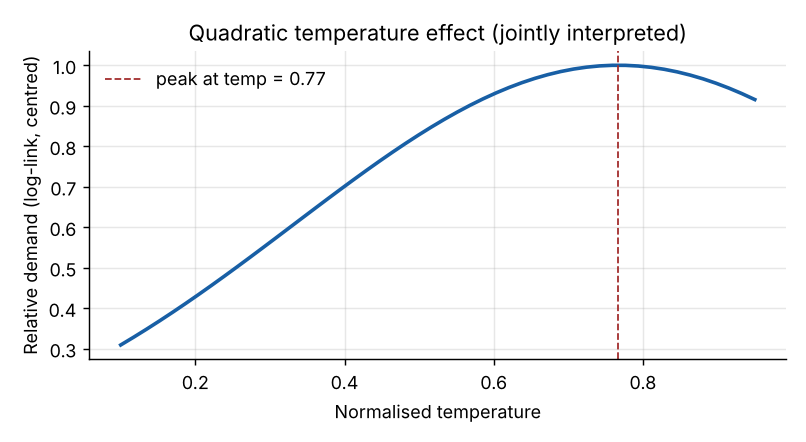

In [3]:
display(pd.read_csv(RES / "02_conditional_coefficients.csv").round(3))
display(pd.read_csv(RES / "03_conditional_validation.csv").round(2))
display(Image(filename=str(RES / "figures" / "temp_effect.png")))


## 3. Task B: one-step-ahead forecasting, backtest and test period

,Model,MAE,RMSE,Poisson deviance
0,Poisson GLM (forecasting),42.91,69.91,13.67
1,Random forest (lag features),56.53,90.95,24.57
2,Seasonal naive (t-168h),57.62,97.92,32.45
3,XGBoost (lag features),58.68,91.40,24.25
4,Naive (t-24h),81.92,137.24,65.78
5,Naive (t-1h),92.22,135.39,57.87
6,Hour x workingday mean,124.39,165.45,88.42
7,Global mean,193.40,253.07,261.15


,Model,mean,std,min,max
0,Poisson GLM (forecasting),44.54,3.08,42.25,48.04
1,XGBoost (lag features),57.41,2.88,55.63,60.73
2,Seasonal naive (t-168h),64.66,2.83,62.70,67.91
3,Naive (t-24h),81.00,5.38,74.80,84.46
4,Naive (t-1h),83.05,2.14,81.41,85.48
5,Hour x workingday mean,103.19,12.60,89.32,113.93
6,Global mean,172.11,11.59,159.12,181.38


,Model,MAE,RMSE,Poisson deviance
0,Poisson GLM (forecasting),41.79,66.87,16.54
1,Random forest (lag features),54.26,85.72,25.74
2,XGBoost (lag features),55.21,84.86,25.11
3,Seasonal naive (t-168h),66.48,112.75,48.49
4,Naive (t-24h),77.77,129.65,64.83
5,Naive (t-1h),81.26,125.43,49.96
6,Hour x workingday mean,103.21,148.91,73.72
7,Global mean,168.89,227.10,224.19


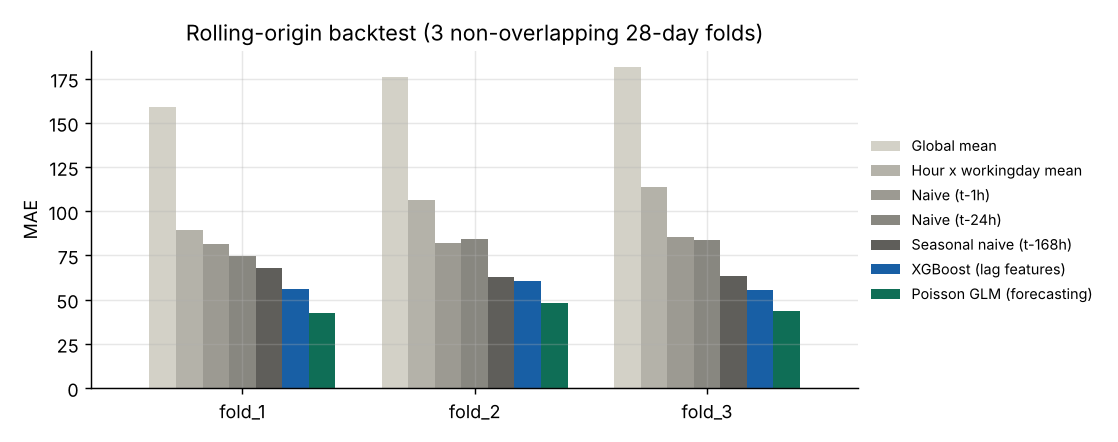

In [4]:
display(pd.read_csv(RES / "04_forecast_validation.csv").round(2))
display(pd.read_csv(RES / "06_backtest_summary.csv").round(2))
display(pd.read_csv(RES / "07_frozen_test_metrics.csv").round(2))
display(Image(filename=str(RES / "figures" / "backtest.png")))


## 4. Conformal intervals under temporal drift

,Method,Coverage,Average width,Winkler score,Coverage below target,Peak-hour coverage,Off-peak coverage,Worst-hour coverage
0,Split / absolute,0.895,188.653,326.728,True,0.780,0.934,0.642
1,Split / Poisson-scaled,0.928,182.880,278.724,False,0.885,0.942,0.816
2,Split / NB-scaled,0.959,273.585,316.729,False,0.966,0.956,0.908
3,Rolling / NB-scaled,0.902,207.833,283.096,False,0.927,0.894,0.762
4,ACI / NB-scaled,0.901,203.583,279.060,False,0.928,0.892,0.780
5,Mondrian / NB-scaled,0.956,275.290,318.328,False,0.965,0.953,0.890


,Method,Coverage,Average width,Winkler score,Coverage below target,Peak-hour coverage,Off-peak coverage,Worst-hour coverage
0,Split / absolute,0.896,186.031,314.178,True,0.770,0.938,0.664
1,Split / Poisson-scaled,0.894,166.053,280.546,True,0.827,0.917,0.776
2,Split / NB-scaled,0.902,232.612,300.488,False,0.895,0.905,0.857
3,Rolling / NB-scaled,0.878,209.025,292.681,True,0.876,0.878,0.810
4,ACI / NB-scaled,0.896,209.522,273.532,True,0.898,0.896,0.822
5,Mondrian / NB-scaled,0.901,234.174,302.341,False,0.887,0.906,0.850


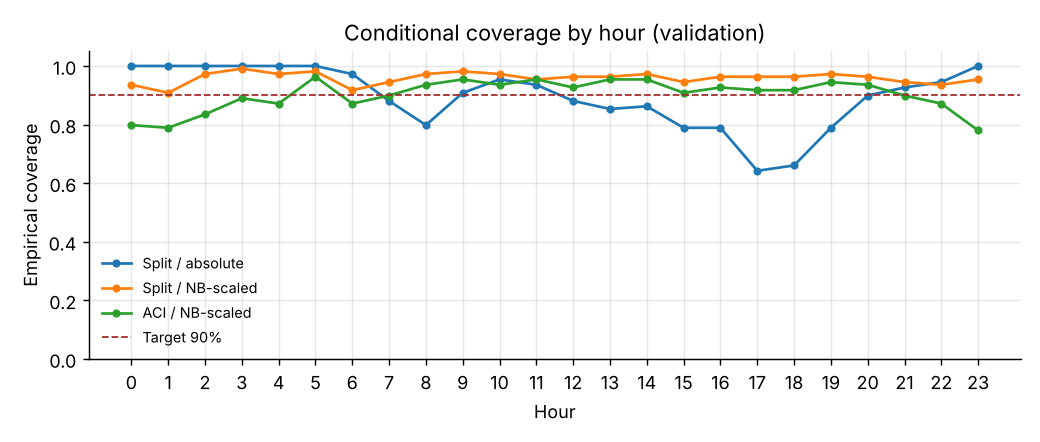

In [5]:
display(pd.read_csv(RES / "11_conformal_validation.csv").round(3))
display(pd.read_csv(RES / "11_conformal_test.csv").round(3))
display(Image(filename=str(RES / "figures" / "coverage_by_hour.png")))


## 5. Diagnostics and honest caveats
Lag-1 residual ACF = 0.73; mean demand rises 229.4 -> 281.6 -> 236.9 across calibration / validation / test. Exchangeability is unlikely to hold, so coverage figures are empirical measurements, not guarantees. See the technical report for the full limitations section.

,Column,Distinct values in validation,Share of rows at modal value
0,yr,1,1.000
1,season,2,0.771
2,mnth,5,0.284


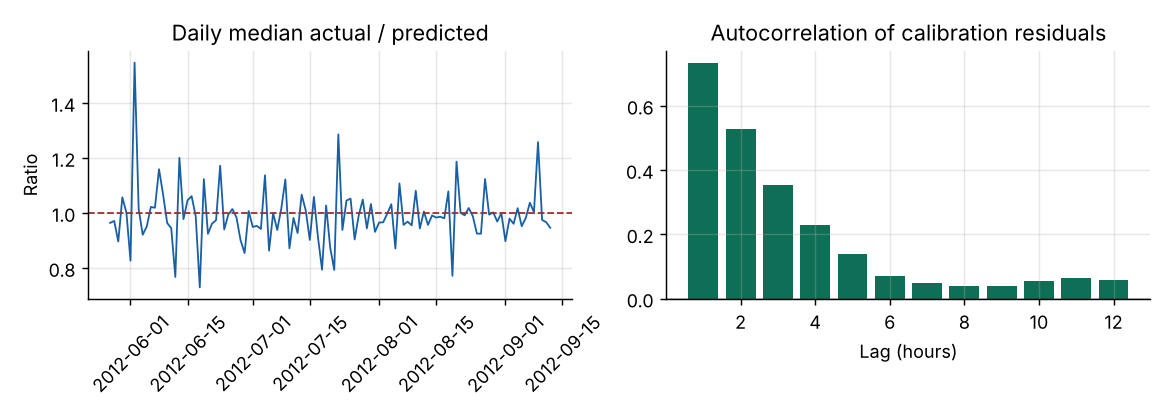

In [6]:
display(pd.read_csv(RES / "10_validation_feature_variation.csv").round(3))
display(Image(filename=str(RES / "figures" / "bias_and_dependence.png")))
